## Student Name: Gabriel Espinoza Rojas

## Student ID: 22176691

# Task 1

## a) Modify your Multinomial Naïve Bayes (MNB) classifier from Etivity5, Task 2, to train and test a sentiment classifier.  [0.5 mark]

<b>Expected Output:</b>

```
posCount=?
negCount=?

probPos=?   probNeg=?

pos_BOW= {...}
neg_BOW= {...}

V = {...}
|V| = ?

----------------------------------------------------
Test document=('Great disappointment indeed', '?')

word= "great              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "disappointment      ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "indeed              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?

docProbPos=?              docProbNeg=?
Inferred class=?
```

In [2]:
import re
import math

def multinomialNaiveBayesClassifier(trainingSet, testSet):
    """
    Multinomial Naive Bayes with add-one (Laplace) smoothing.
    From e-tivity 5:
    GB -> NEG
    IE -> POS
    """

    # first the mega-documents Dan talks about, simply just concatenate all documents for each class into just one
    megaDocNEG = ""
    megaDocPOS = ""
    pseudo_V = ""
    # to calculate priors
    NEG_total_count = 0
    POS_total_count = 0

    # training loop
    for pair in trainingSet:
        # stripping punctuation since I noticed in task 1 it could create problems
        document = " ".join(re.findall(r"\w+", pair[0]))
        class_id = pair[1]
        if class_id == "-":
            NEG_total_count = NEG_total_count + 1
            megaDocNEG = megaDocNEG + document + " "
        else:
            # if an input had any other class this would be wrong (other than +)
            POS_total_count = POS_total_count + 1
            megaDocPOS = megaDocPOS + document + " "

        # incomplete V, needs to drop duplicates later on
        pseudo_V = pseudo_V + document + " "

    # normalising to lower case
    # and drop the last space concatenated, not needed
    megaDocNEG = megaDocNEG[:-1].lower()
    megaDocPOS = megaDocPOS[:-1].lower()
    pseudo_V = pseudo_V[:-1].lower()

    print(f"posCount= {len(megaDocPOS.split(" "))}")
    print(f"negCount= {len(megaDocNEG.split(" "))}\n")


    # How many times does the class - occurs in our training set out of the how many total documents are there in our training set?
    probNEG = NEG_total_count/len(trainingSet)
    # How many times does the class + occurs in our training set out of the how many total documents are there in our training set?
    probPOS = POS_total_count/len(trainingSet)

    # priors (think of each class as a language model, unigrams)
    print(f"probPos= {probPOS}   probNeg= {probNEG}\n")

    NEG_BOW = {}
    for token in megaDocNEG.split(" "):
        if NEG_BOW.get(token) is not None:
            NEG_BOW[token] = NEG_BOW[token] + 1
        else:
            NEG_BOW[token] = 1

    POS_BOW = {}
    for token in megaDocPOS.split(" "):
        if POS_BOW.get(token) is not None:
            POS_BOW[token] = POS_BOW[token] + 1
        else:
            POS_BOW[token] = 1

    print(f"pos_BOW= {POS_BOW}")
    print(f"neg_BOW= {NEG_BOW}\n")

    V = {}
    # let's use the pseudo V (minus the extra space) to build the V dictionary
    for token in pseudo_V.split(" "):
        if V.get(token) is not None:
            V[token] = V[token] + 1
        else:
            V[token] = 1

    print(f"V = {V}")
    V_count = len(V)
    print(f"|V| = {V_count}\n")

    print("------------------------------------------------")
    for test_document in testSet:
        print(f"Test document={test_document}\n")

        document = test_document[0]

        NEG_conditional_probabilities = 1
        POS_conditional_probabilities = 1

        # every word must be accounted for as a conditional probability (for both classes)
        # test documents also need to be normalised (no CAPS)
        for token in re.findall(r"\w+", document.lower()):
            # not really every word tho, Dan said that non words (not present in our training docs) are complete ignored
            if V.get(token) is not None:
                #P(w_i|c) = \frac{count(w_i, c) + 1}{count(c) + |V|} with c = class and w_i the token
                wordConditionalProbNEG = ((NEG_BOW.get(token) if NEG_BOW.get(token) is not None else 0) + 1)/(sum(NEG_BOW.values()) + V_count)
                wordConditionalProbPOS = ((POS_BOW.get(token) if POS_BOW.get(token) is not None else 0) + 1)/(sum(POS_BOW.values()) + V_count)
                NEG_conditional_probabilities = NEG_conditional_probabilities * wordConditionalProbNEG
                POS_conditional_probabilities = POS_conditional_probabilities * wordConditionalProbPOS
                print(f"word = \"{token}    \", wordConditionalProbPos= {wordConditionalProbPOS},       wordConditionalProbNeg= {wordConditionalProbNEG}")
            else:
                print(f"word = \"{token}    \", wordConditionalProbPos= {"N/A"},    wordConditionalProbNeg= {"N/A"}")


        print("\n")

        # P(-|test_document) ∝ P(-) * prod P(w|-)
        docProbNEG = probNEG * NEG_conditional_probabilities
        # P(+|test_document) ∝ P(+) * prod P(w|+)
        docProbPOS = probPOS * POS_conditional_probabilities
        print(f"docProbPos= {docProbPOS},   docProbNeg= {docProbNEG}")

        winner = ""
        # https://www.w3schools.com/python/ref_math_isclose.asp
        if math.isclose(docProbNEG, docProbPOS):
            winner = 'tie'
        elif docProbNEG > docProbPOS:
            winner = '-'
        else:
            winner = '+'

        print(f"Inferred class= {winner}")
        print("------------------------------------------------")



trainingSet = [('Boxing scene was a disappointment','-'),
               ('No plot twists or great scenes','-'),
               ('Great satire and great plot twists','+'),
               ('Great scenes a great film','+')]

testSet = [('Great disappointment indeed','?')]
multinomialNaiveBayesClassifier(trainingSet,testSet)

posCount= 11
negCount= 11

probPos= 0.5   probNeg= 0.5

pos_BOW= {'great': 4, 'satire': 1, 'and': 1, 'plot': 1, 'twists': 1, 'scenes': 1, 'a': 1, 'film': 1}
neg_BOW= {'boxing': 1, 'scene': 1, 'was': 1, 'a': 1, 'disappointment': 1, 'no': 1, 'plot': 1, 'twists': 1, 'or': 1, 'great': 1, 'scenes': 1}

V = {'boxing': 1, 'scene': 1, 'was': 1, 'a': 2, 'disappointment': 1, 'no': 1, 'plot': 2, 'twists': 2, 'or': 1, 'great': 5, 'scenes': 2, 'satire': 1, 'and': 1, 'film': 1}
|V| = 14

------------------------------------------------
Test document=('Great disappointment indeed', '?')

word = "great    ", wordConditionalProbPos= 0.2,       wordConditionalProbNeg= 0.08
word = "disappointment    ", wordConditionalProbPos= 0.04,       wordConditionalProbNeg= 0.08
word = "indeed    ", wordConditionalProbPos= N/A,    wordConditionalProbNeg= N/A


docProbPos= 0.004,   docProbNeg= 0.0032
Inferred class= +
------------------------------------------------


## b) Copy your solution for (a) into a new code cell.  Modify your code to optimise it for the task of sentiment analysis, i.e., change your classification algorithm from MNB to BMNB (Binary Multinomial Naïve Bayes). [2 marks]

<b>Expected Output:</b>

```
posCount=?
negCount=?

probPos=?   probNeg=?

pos_BOW= {...}
neg_BOW= {...}

V = {...}
|V| = ?

----------------------------------------------------
Test document=('Great disappointment indeed', '?')

word= "great              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "disappointment      ",    wordConditionalProbPos=?    wordConditionalProbNeg=?
word= "indeed              ",    wordConditionalProbPos=?    wordConditionalProbNeg=?

docProbPos=?              docProbNeg=?
Inferred class=?
```

In [9]:
# Dan video about Binary NB https://youtu.be/tjDceq0qH10?list=PLAUFqkTvH_MQ&t=318

def binaryMultinomialNaiveBayesClassifier(trainingSet,testSet):
    """
    Binary Multinomial Naive Bayes with add-one (Laplace) smoothing.
    """

    # first the mega-documents Dan talks about, simply just concatenate all documents for each class into just one
    megaDocNEG = ""
    megaDocPOS = ""
    pseudo_V = ""
    # to calculate priors
    NEG_total_count = 0
    POS_total_count = 0

    # training loop
    for pair in trainingSet:
        # stripping punctuation since I noticed in task 1 it could create problems
        # dict.fromkeys drops repeated words, Jurafsky explains "for NMNB remove duplicates in each doc, retain only a single instance of w"
        document = " ".join(dict.fromkeys(re.findall(r"\w+", pair[0].lower())))
        class_id = pair[1]
        if class_id == "-":
            NEG_total_count = NEG_total_count + 1
            megaDocNEG = megaDocNEG + document + " "
        else:
            # if an input had any other class this would be wrong (other than +)
            POS_total_count = POS_total_count + 1
            megaDocPOS = megaDocPOS + document + " "

        # incomplete V, needs to drop duplicates later on
        pseudo_V = pseudo_V + document + " "

    # normalising to lower case
    # and drop the last space concatenated, not needed
    megaDocNEG = megaDocNEG[:-1].lower()
    megaDocPOS = megaDocPOS[:-1].lower()
    pseudo_V = pseudo_V[:-1].lower()

    # How many times does the class - occurs in our training set out of the how many total documents are there in our training set?
    probNEG = NEG_total_count/len(trainingSet)
    # How many times does the class + occurs in our training set out of the how many total documents are there in our training set?
    probPOS = POS_total_count/len(trainingSet)

    NEG_BOW = {}
    for token in megaDocNEG.split(" "):
        NEG_BOW[token] = NEG_BOW.get(token, 0) + 1
        
    POS_BOW = {}
    for token in megaDocPOS.split(" "):
        POS_BOW[token] = POS_BOW.get(token, 0) + 1

    print(f"posCount= {sum(POS_BOW.values())}")
    print(f"negCount= {sum(NEG_BOW.values())}\n")

    # priors (think of each class as a language model, unigrams)
    print(f"probPos= {probPOS}   probNeg= {probNEG}\n")
    
    print(f"pos_BOW= {POS_BOW}")
    print(f"neg_BOW= {NEG_BOW}\n")

    V = {}
    # let's use the pseudo V (minus the extra space) to build the V dictionary
    for token in pseudo_V.split(" "):
        if V.get(token) is not None:
            V[token] = V[token] + 1
        else:
            V[token] = 1

    print(f"V = {V}")
    V_count = len(V)
    print(f"|V| = {V_count}\n")

    print("------------------------------------------------")
    for test_document in testSet:
        print(f"Test document={test_document}\n")

        document = test_document[0]

        NEG_conditional_probabilities = 1
        POS_conditional_probabilities = 1

        # every word must be accounted for as a conditional probability (for both classes)
        # test documents also need to be normalised (no CAPS)
        for token in re.findall(r"\w+", document.lower()):
            # not really every word tho, Dan said that non words (not present in our training docs) are complete ignored
            if V.get(token) is not None:
                #P(w_i|c) = \frac{count(w_i, c) + 1}{count(c) + |V|} with c = class and w_i the token
                wordConditionalProbNEG = ((NEG_BOW.get(token) if NEG_BOW.get(token) is not None else 0) + 1)/(sum(NEG_BOW.values()) + V_count)
                wordConditionalProbPOS = ((POS_BOW.get(token) if POS_BOW.get(token) is not None else 0) + 1)/(sum(POS_BOW.values()) + V_count)
                NEG_conditional_probabilities = NEG_conditional_probabilities * wordConditionalProbNEG
                POS_conditional_probabilities = POS_conditional_probabilities * wordConditionalProbPOS
                print(f"word = \"{token}    \", wordConditionalProbPos= {wordConditionalProbPOS},       wordConditionalProbNeg= {wordConditionalProbNEG}")
            else:
                print(f"word = \"{token}    \", wordConditionalProbPos= {"N/A"},    wordConditionalProbNeg= {"N/A"}")


        print("\n")

        # P(-|test_document) ∝ P(-) * prod P(w|-)
        docProbNEG = probNEG * NEG_conditional_probabilities
        # P(+|test_document) ∝ P(+) * prod P(w|+)
        docProbPOS = probPOS * POS_conditional_probabilities
        print(f"docProbPos= {docProbPOS},   docProbNeg= {docProbNEG}")

        winner = ""
        # https://www.w3schools.com/python/ref_math_isclose.asp
        if math.isclose(docProbNEG, docProbPOS):
            winner = 'tie'
        elif docProbNEG > docProbPOS:
            winner = '-'
        else:
            winner = '+'

        print(f"Inferred class= {winner}")
        print("------------------------------------------------")



trainingSet = [('Boxing scene was a disappointment','-'),
               ('No plot twists or great scenes','-'),
               ('Great satire and great plot twists','+'),
               ('Great scenes a great film','+')]

testSet = [('Great disappointment indeed','?')]

binaryMultinomialNaiveBayesClassifier(trainingSet,testSet)

posCount= 9
negCount= 11

probPos= 0.5   probNeg= 0.5

pos_BOW= {'great': 2, 'satire': 1, 'and': 1, 'plot': 1, 'twists': 1, 'scenes': 1, 'a': 1, 'film': 1}
neg_BOW= {'boxing': 1, 'scene': 1, 'was': 1, 'a': 1, 'disappointment': 1, 'no': 1, 'plot': 1, 'twists': 1, 'or': 1, 'great': 1, 'scenes': 1}

V = {'boxing': 1, 'scene': 1, 'was': 1, 'a': 2, 'disappointment': 1, 'no': 1, 'plot': 2, 'twists': 2, 'or': 1, 'great': 3, 'scenes': 2, 'satire': 1, 'and': 1, 'film': 1}
|V| = 14

------------------------------------------------
Test document=('Great disappointment indeed', '?')

word = "great    ", wordConditionalProbPos= 0.13043478260869565,       wordConditionalProbNeg= 0.08
word = "disappointment    ", wordConditionalProbPos= 0.043478260869565216,       wordConditionalProbNeg= 0.08
word = "indeed    ", wordConditionalProbPos= N/A,    wordConditionalProbNeg= N/A


docProbPos= 0.0028355387523629487,   docProbNeg= 0.0032
Inferred class= -
------------------------------------------------


## c) Copy your solution for (b) into a new code cell.  Enhance your code to measure the performance of the BMNB classifier in terms of accuracy, precision, recall, and F1. [1.5 marks]

<b>Expected Output:</b>

```
posCount= ?
negCount= ?

probPos= ? probNeg= ?

pos_BOW= ?
neg_BOW= ?

V = ?
|V| = ?

----------------------------------------------------
Test document=('Great disappointment indeed', '-')


word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?
word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?
word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?


docProbPos=            ?,	 docProbNeg=            ?
Inferred class= ?
----------------------------------------------------

[... results for 8 additional test documents to appear here ...]

----------------------------------------------------
Test document=('nice film', '+')

word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?
word= ?,	 wordConditionalProbPos= ?,	 wordConditionalProbNeg= ?

docProbPos=            ?,	 docProbNeg=            ?
Inferred class= ?
----------------------------------------------------

TP= ?	 TN= ?
FP= ?	 FN= ?

Accuracy= ?

Precision= ?

Recall= ?

F1= ?
```

In [ ]:
# Dan video about Binary NB https://youtu.be/tjDceq0qH10?list=PLAUFqkTvH_MQ&t=318

def binaryMultinomialNaiveBayesClassifier(trainingSet,testSet):
    """
    Binary Multinomial Naive Bayes with add-one (Laplace) smoothing.
    """

    # first the mega-documents Dan talks about, simply just concatenate all documents for each class into just one
    megaDocNEG = ""
    megaDocPOS = ""
    pseudo_V = ""
    # to calculate priors
    NEG_total_count = 0
    POS_total_count = 0

    # training loop
    for pair in trainingSet:
        # stripping punctuation since I noticed in task 1 it could create problems
        # dict.fromkeys drops repeated words, Jurafsky explains "for NMNB remove duplicates in each doc, retain only a single instance of w"
        document = " ".join(dict.fromkeys(re.findall(r"\w+", pair[0].lower())))
        class_id = pair[1]
        if class_id == "-":
            NEG_total_count = NEG_total_count + 1
            megaDocNEG = megaDocNEG + document + " "
        else:
            # if an input had any other class this would be wrong (other than +)
            POS_total_count = POS_total_count + 1
            megaDocPOS = megaDocPOS + document + " "

        # incomplete V, needs to drop duplicates later on
        pseudo_V = pseudo_V + document + " "

    # normalising to lower case
    # and drop the last space concatenated, not needed
    megaDocNEG = megaDocNEG[:-1].lower()
    megaDocPOS = megaDocPOS[:-1].lower()
    pseudo_V = pseudo_V[:-1].lower()

    # How many times does the class - occurs in our training set out of the how many total documents are there in our training set?
    probNEG = NEG_total_count/len(trainingSet)
    # How many times does the class + occurs in our training set out of the how many total documents are there in our training set?
    probPOS = POS_total_count/len(trainingSet)

    NEG_BOW = {}
    for token in megaDocNEG.split(" "):
        NEG_BOW[token] = NEG_BOW.get(token, 0) + 1
        
    POS_BOW = {}
    for token in megaDocPOS.split(" "):
        POS_BOW[token] = POS_BOW.get(token, 0) + 1

    print(f"posCount= {sum(POS_BOW.values())}")
    print(f"negCount= {sum(NEG_BOW.values())}\n")

    # priors (think of each class as a language model, unigrams)
    print(f"probPos= {probPOS}   probNeg= {probNEG}\n")

    print(f"pos_BOW= {POS_BOW}")
    print(f"neg_BOW= {NEG_BOW}\n")

    V = {}
    # let's use the pseudo V (minus the extra space) to build the V dictionary
    for token in pseudo_V.split(" "):
        if V.get(token) is not None:
            V[token] = V[token] + 1
        else:
            V[token] = 1

    print(f"V = {V}")
    V_count = len(V)
    print(f"|V| = {V_count}\n")

    print("------------------------------------------------")

    BMBN_predictions = []

    for test_document in testSet:
        print(f"Test document={test_document}\n")

        document = test_document[0]

        NEG_conditional_probabilities = 1
        POS_conditional_probabilities = 1

        # every word must be accounted for as a conditional probability (for both classes)
        # test documents also need to be normalised (no CAPS)
        for token in re.findall(r"\w+", document.lower()):
            # not really every word tho, Dan said that non words (not present in our training docs) are complete ignored
            if V.get(token) is not None:
                #P(w_i|c) = \frac{count(w_i, c) + 1}{count(c) + |V|} with c = class and w_i the token
                wordConditionalProbNEG = ((NEG_BOW.get(token) if NEG_BOW.get(token) is not None else 0) + 1)/(sum(NEG_BOW.values()) + V_count)
                wordConditionalProbPOS = ((POS_BOW.get(token) if POS_BOW.get(token) is not None else 0) + 1)/(sum(POS_BOW.values()) + V_count)
                NEG_conditional_probabilities = NEG_conditional_probabilities * wordConditionalProbNEG
                POS_conditional_probabilities = POS_conditional_probabilities * wordConditionalProbPOS
                print(f"word = \"{token}    \", wordConditionalProbPos= {wordConditionalProbPOS},       wordConditionalProbNeg= {wordConditionalProbNEG}")
            else:
                print(f"word = \"{token}    \", wordConditionalProbPos= {"N/A"},    wordConditionalProbNeg= {"N/A"}")


        print("\n")

        # P(-|test_document) ∝ P(-) * prod P(w|-)
        docProbNEG = probNEG * NEG_conditional_probabilities
        # P(+|test_document) ∝ P(+) * prod P(w|+)
        docProbPOS = probPOS * POS_conditional_probabilities
        print(f"docProbPos= {docProbPOS},   docProbNeg= {docProbNEG}")

        winner = ""
        # https://www.w3schools.com/python/ref_math_isclose.asp
        if math.isclose(docProbNEG, docProbPOS):
            winner = 'tie'
        elif docProbNEG > docProbPOS:
            winner = '-'
        else:
            winner = '+'

        print(f"Inferred class= {winner}")

        BMBN_predictions = BMBN_predictions + [(test_document, winner)]
        print("------------------------------------------------")


    # true positives
    TP = 0
    # true negatives
    TN = 0
    # false positives 
    FP = 0
    # false negatives
    FN = 0

    for document_and_prediction in BMBN_predictions:
        golden_label = document_and_prediction[0][1]
        prediction = document_and_prediction[1]

        if(golden_label == prediction == "-"):
            TN = TN + 1
        elif (golden_label == prediction == "+"):
            TP = TP + 1
        elif (golden_label == "-" and prediction == "+"):
            FP = FP + 1
        elif (golden_label == "+" and prediction == "-"):
            FN = FN + 1

    
    Accuracy = (TP + TN)/(TP + FP + TN + FN)
    
    Precision = (TP)/(TP + FP)

    Recall = (TP)/(TP + FN)

    F1 = (2*Precision*Recall)/(Precision + Recall)

    print(f"TP= {TP}	 TN= {TN}")
    print(f"FP= {FP}	 FN= {FN}")
    print(f"Accuracy= {Accuracy}")
    print(f"Precision= {Precision}")
    print(f"Recall= {Recall}")
    print(f"F1= {F1}")

trainingSet = [('Boxing scene was a disappointment','-'),
               ('No plot twists or great scenes','-'),
               ('Great satire and great plot twists','+'),
               ('Great scenes a great film','+')]


testSet = [('Great disappointment indeed','-'), 
           ('What a great movie','+'), 
           ('Great satire','+'), 
           ('No plot twists or satire','-'), 
           ('This movie was a disappointment','-'), 
           ('great disappointment','-'), 
           ('great boxing scenes','+'), 
           ('great movie','+'), 
           ('bad film','-'), 
           ('nice film','+')]


binaryMultinomialNaiveBayesClassifier(trainingSet,testSet)

posCount= 2
negCount= 2

probPos= 0.5   probNeg= 0.5

posCount= 9
negCount= 11

pos_BOW= {'great': 2, 'satire': 1, 'and': 1, 'plot': 1, 'twists': 1, 'scenes': 1, 'a': 1, 'film': 1}
neg_BOW= {'boxing': 1, 'scene': 1, 'was': 1, 'a': 1, 'disappointment': 1, 'no': 1, 'plot': 1, 'twists': 1, 'or': 1, 'great': 1, 'scenes': 1}

V = {'boxing': 1, 'scene': 1, 'was': 1, 'a': 2, 'disappointment': 1, 'no': 1, 'plot': 2, 'twists': 2, 'or': 1, 'great': 3, 'scenes': 2, 'satire': 1, 'and': 1, 'film': 1}
|V| = 14

------------------------------------------------
Test document=('Great disappointment indeed', '-')

word = "great    ", wordConditionalProbPos= 0.13043478260869565,       wordConditionalProbNeg= 0.08
word = "disappointment    ", wordConditionalProbPos= 0.043478260869565216,       wordConditionalProbNeg= 0.08
word = "indeed    ", wordConditionalProbPos= N/A,    wordConditionalProbNeg= N/A


docProbPos= 0.0028355387523629487,   docProbNeg= 0.0032
Inferred class= -
-----------------------------

video About F1 and other metrics... https://youtu.be/mjOgb4T7yyo?list=PLAUFqkTvH_MQ&t=16 
https://youtu.be/mjOgb4T7yyo?list=PLAUFqkTvH_MQ&t=667

different video: we can use the confusion matrix to calculate R, P and F1 too:
https://youtu.be/NjhVTN19JDI?list=PLAUFqkTvH_MQ&t=132

# Task 2

Write a Sentiment Analysis function that takes a string as input and identifies its sentiment using the [TextBlob library](https://textblob.readthedocs.io/en/dev/quickstart.html#sentiment-analysis). Pay attention to the sentiment of the last two test cases.

<b>Expected Output:</b>

```
String= NLP is cool

Sentiment(polarity=0.35, subjectivity=0.65)
Positive sentiment 😊
Subjectivity: 0.65
---------------------------------

String= NLP is cool and useful

Sentiment(polarity=0.32499999999999996, subjectivity=0.325)
Positive sentiment 😊
Subjectivity: 0.325
---------------------------------

String= NLP is hard

Sentiment(polarity=-0.2916666666666667, subjectivity=0.5416666666666666)
Negative sentiment 😞
Subjectivity: 0.5416666666666666
---------------------------------

String= NLP is hard and useless

Sentiment(polarity=-0.39583333333333337, subjectivity=0.37083333333333335)
Negative sentiment 😞
Subjectivity: 0.37083333333333335
---------------------------------

String= NLP stands for Natural Language Processing

Sentiment(polarity=0.1, subjectivity=0.4)
Neutral sentiment 😐 (pay attention to this)
Subjectivity: 0.4
---------------------------------

String= NLP stands for Natural Language Processing and it can be hard sometimes

Sentiment(polarity=-0.09583333333333334, subjectivity=0.4708333333333333)
Neutral sentiment 😐 (pay attention to this)
Subjectivity: 0.4708333333333333
---------------------------------
```


In [4]:
#Taken from previous e-tivity
import pandas as pd

!wget http://ptrckprry.com/course/ssd/data/positive-words.txt   #Opinion Lexicon: Positive Words; source: http://www.cs.uic.edu/~liub/FBS/sentiment-analysis.html
!wget http://ptrckprry.com/course/ssd/data/negative-words.txt   #Opinion Lexicon: Negative Words; source: http://www.cs.uic.edu/~liub/FBS/sentiment-analysis.html

filePath1 = "/content/positive-words.txt"
filePath2 = "/content/negative-words.txt"

#Latin-1 (ISO-8859-1) character set. Use chardet lib if needed.
#skiprows drops the licence header at the top of each file.
posWords_df = pd.read_csv(filePath1, sep='\t', header=None, names=['words'], encoding='latin-1', skiprows=[i for i in range(0,34)])
negWords_df = pd.read_csv(filePath2, sep='\t', header=None, names=['words'], encoding='latin-1', skiprows=[i for i in range(0,34)])

print(f'Number of posWords: {len(posWords_df)}   Number of negWords: {negWords_df.size}')
display(posWords_df.head(10))
display(negWords_df.head(10))

--2026-10-24 02:06:02--  http://ptrckprry.com/course/ssd/data/positive-words.txt
Resolving ptrckprry.com (ptrckprry.com)... 185.199.110.153, 185.199.109.153, 185.199.108.153, ...
Connecting to ptrckprry.com (ptrckprry.com)|185.199.110.153|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://ptrckprry.com/course/ssd/data/positive-words.txt [following]
--2026-10-24 02:06:02--  https://ptrckprry.com/course/ssd/data/positive-words.txt
Connecting to ptrckprry.com (ptrckprry.com)|185.199.110.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 20630 (20K) [text/plain]
Saving to: ‘positive-words.txt.7’

positive-words.txt. 100%[===================>]  20.15K  --.-KB/s    in 0.002s  

2026-10-24 02:06:02 (9.63 MB/s) - ‘positive-words.txt.7’ saved [20630/20630]

--2026-10-24 02:06:02--  http://ptrckprry.com/course/ssd/data/negative-words.txt
Resolving ptrckprry.com (ptrckprry.com)... 185.199.110.153, 185.199.109.153, 185.199.1

,words
0,a+
1,abound
2,abounds
3,abundance
4,abundant
5,accessable
6,accessible
7,acclaim
8,acclaimed
9,acclamation


,words
0,2-faced
1,2-faces
2,abnormal
3,abolish
4,abominable
5,abominably
6,abominate
7,abomination
8,abort
9,aborted


In [5]:
# The base for this code was taken from previous e-tivity
from textblob import TextBlob

def sentimentAnalyzer(string):
    """
    Rule-based sentiment using TextBlob.sentiment
    'The sentiment property returns a namedtuple of the form Sentiment(polarity, subjectivity)'
    """
    
    print(f"\nstring= {string}\n")

    testimonial = TextBlob(string)

    print(f"{testimonial.sentiment}")
    
    # The polarity score is a float within the range [-1.0, 1.0]. 
    polarity = testimonial.sentiment.polarity

    # The subjectivity is a float within the range [0.0, 1.0] where 0.0 is very objective and 1.0 is very subjective.
    subjectivity = testimonial.sentiment.subjectivity

    # If math.isclose(polarity, 0) and math.isclose(subjectivity, 0.5) → neutral
    if  0.1 >= polarity >= -0.9 and 0.5 >= subjectivity >= 0.4:
        # I'll need to come back to this  
        print(f"neutral sentiment 😶")
    else:
        # If positive appearances > negative appearances → positive sentiment 
        if polarity > 0:
            print(f"Positive sentiment 🥹")
        else:
            # and vice versa
            print(f"Negative sentiment 😞")
            # emojis taken from: https://www.webfx.com/tools/emoji-cheat-sheet/
    
    print(f"Subjectivity: {subjectivity}")
    
    print("--------------------------------")

sentimentAnalyzer("NLP is cool")
sentimentAnalyzer("NLP is cool and useful")
sentimentAnalyzer("NLP is hard")
sentimentAnalyzer("NLP is hard and useless")
sentimentAnalyzer("NLP stands for Natural Language Processing")
sentimentAnalyzer("NLP stands for Natural Language Processing and it can be hard sometimes")


string= NLP is cool

Sentiment(polarity=0.35, subjectivity=0.65)
Positive sentiment 🥹
Subjectivity: 0.65
--------------------------------

string= NLP is cool and useful

Sentiment(polarity=0.32499999999999996, subjectivity=0.325)
Positive sentiment 🥹
Subjectivity: 0.325
--------------------------------

string= NLP is hard

Sentiment(polarity=-0.2916666666666667, subjectivity=0.5416666666666666)
Negative sentiment 😞
Subjectivity: 0.5416666666666666
--------------------------------

string= NLP is hard and useless

Sentiment(polarity=-0.39583333333333337, subjectivity=0.37083333333333335)
Negative sentiment 😞
Subjectivity: 0.37083333333333335
--------------------------------

string= NLP stands for Natural Language Processing

Sentiment(polarity=0.1, subjectivity=0.4)
neutral sentiment 😶
Subjectivity: 0.4
--------------------------------

string= NLP stands for Natural Language Processing and it can be hard sometimes

Sentiment(polarity=-0.09583333333333334, subjectivity=0.47083333333

# Task 3

Write a Python code snippet to:
1. Download the BBC text classification dataset from https://storage.googleapis.com/dataset-uploader/bbc/bbc-text.csv

2. Explore the dataset and print out: 

    a. The total number of documents in the dataset
    
    b. The total number of documents per class (is the dataset balanced?)
    
    c. One sample document per class 
[1 mark]

3. Split the data into training and test sets (**80/20** training/test split) using your own <code>train_test_split()</code> Function.

4. Use the [textblob.classifiers](https://textblob.readthedocs.io/en/dev/classifiers.html) module to train and test a Naive Bayes classifier and print out the model’s accuracy. [1.5 marks]

5. Re-evaluate the model using 2-fold cross-validation. [1.5 marks]

Note 1: Given the relatively large size of the BBC dataset, the training and testing process could take a few minutes. In case of experiencing an out-of-memory error (after multiple runs), restart your VM (Runtime -> Restart Session).

Note 2: You can first develop and test your code using a small subset of the dataset (e.g. 100 docs). Once you are happy with the results, proceed to using the full dataset for one last run.


## 1. Download the BBC text classification dataset

In [6]:
# load dataset
import pandas as pd

!wget https://storage.googleapis.com/download.tensorflow.org/data/bbc-text.csv

filePath1 = "/content/bbc-text.csv"

df = pd.read_csv(filePath1)

--2026-10-24 02:06:05--  https://storage.googleapis.com/download.tensorflow.org/data/bbc-text.csv
Resolving storage.googleapis.com (storage.googleapis.com)... 34.3.0.27, 104.154.124.27, 34.144.170.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|34.3.0.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5057493 (4.8M) [text/csv]
Saving to: ‘bbc-text.csv.8’

bbc-text.csv.8      100%[===================>]   4.82M  --.-KB/s    in 0.02s   

2026-10-24 02:06:05 (277 MB/s) - ‘bbc-text.csv.8’ saved [5057493/5057493]



## 2. Explore the dataset and print out: 

    

### a. The total number of documents in the dataset

In [7]:
print(f'Total number of ocuments in the dataset: {len(df)}')

Total number of ocuments in the dataset: 2225


### b. The total number of documents per class (is the dataset balanced?)

,category,text
count,2225,2225
unique,5,2126
top,sport,blind student hears in colour a blind studen...
freq,511,2


Count for category tech 401
Count for category business 510
Count for category sport 511
Count for category entertainment 386
Count for category politics 417


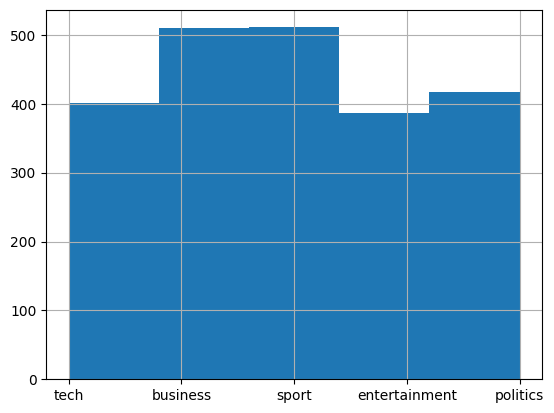

In [8]:
# Print statistical summary for all numerical attributes
display(df.describe())

(df['category'].hist(bins=5))

print(f"Count for category tech {(df['category'] == 'tech').sum()}")
print(f"Count for category business {(df['category'] == 'business').sum()}")
print(f"Count for category sport {(df['category'] == 'sport').sum()}")
print(f"Count for category entertainment {(df['category'] == 'entertainment').sum()}")
print(f"Count for category politics {(df['category'] == 'politics').sum()}")


I used described to see how many unique categories the dataset has. I'd say it is balanced.

### c. One sample document per class 

In [9]:
print(f"Sample document for class tech:\n\"{(df.loc[df['category'] == 'tech']).values[0][1]}\"")
print(f"Sample document for class business:\n\"{(df.loc[df['category'] == 'business']).values[0][1]}\"")
print(f"Sample document for class sport:\n\"{(df.loc[df['category'] == 'sport']).values[0][1]}\"")
print(f"Sample document for class entertainment:\n\"{(df.loc[df['category'] == 'entertainment']).values[0][1]}\"")
print(f"Sample document for class politics:\n\"{(df.loc[df['category'] == 'politics']).values[0][1]}\"")

Sample document for class tech:
"tv future in the hands of viewers with home theatre systems  plasma high-definition tvs  and digital video recorders moving into the living room  the way people watch tv will be radically different in five years  time.  that is according to an expert panel which gathered at the annual consumer electronics show in las vegas to discuss how these new technologies will impact one of our favourite pastimes. with the us leading the trend  programmes and other content will be delivered to viewers via home networks  through cable  satellite  telecoms companies  and broadband service providers to front rooms and portable devices.  one of the most talked-about technologies of ces has been digital and personal video recorders (dvr and pvr). these set-top boxes  like the us s tivo and the uk s sky+ system  allow people to record  store  play  pause and forward wind tv programmes when they want.  essentially  the technology allows for much more personalised tv. they

## 3. Split the data into training and test sets (**80/20** training/test split) using your own <code>train_test_split()</code> Function.


In [10]:
def train_test_split(df):
    """
    My own implementation of the famous function from scikit learn (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
    seed and split values not exposed
    80/20 training/test split
    """
    
    samples = list(zip(df['text'], df['category']))

    # random.Random(42).shuffle(samples) # do I need to shuffle?

    X_train, y_test = [], []

    X_train = samples[:int(len(samples)*0.8)]
    y_test = samples[int(len(samples)*0.8):]

    print(f"size of training set: {len(X_train)}, size of testing set: {len(y_test)}")

    return X_train, y_test 

X_train_T3, y_test_T3 = train_test_split(df)

size of training set: 1780, size of testing set: 445


## 4. Use the [textblob.classifiers](https://textblob.readthedocs.io/en/dev/classifiers.html) module to train and test a Naive Bayes classifier and print out the model’s accuracy. [1.5 marks]

In [11]:
import nltk
# extra requirement to download punkt
!python -m textblob.download_corpora
nltk.download('punkt')
from textblob.classifiers import NaiveBayesClassifier


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package conll2000 to /root/nltk_data...
[nltk_data]   Package conll2000 is already up-to-date!
[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Package movie_reviews is already up-to-date!
Finished.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
classifier = NaiveBayesClassifier(X_train_T3)

classifier.accuracy(y_test_T3)

0.9707865168539326

: 

## 5. Re-evaluate the model using 2-fold cross-validation. [1.5 marks]

In [13]:
# scikit-learn k-fold cross-validation (https://machinelearningmastery.com/k-fold-cross-validation/)
from numpy import array
from sklearn.model_selection import KFold

samples = list(zip(df['text'], df['category']))

# prepare cross validation
kfold = KFold(2)

# for evaluation
scores = []

# enumerate splits
for train, test in kfold.split(samples):
	train_fold = [samples[i] for i in train]
	test_fold = [samples[i] for i in test]
	acc = NaiveBayesClassifier(train_fold).accuracy(test_fold)
	scores.append(acc)
	print(f"train: {len(train_fold)}, test: {len(test_fold)}, accuracy: {acc:.3f}")

print(f"mean accuracy over 2 folds: {sum(scores)/len(scores):.3f}")

: 

: 

# Task 4 

Write a function that takes sets of training and test documents as input and uses the [textblob.classifiers](https://textblob.readthedocs.io/en/dev/classifiers.html) module to:

 a) train a Naive Bayes classifier using the provided training set.

 b) evaluate the performance of the model and print its accuracy. 

 c***) explain why the class of the last test document is predicted to be “GB” or “Ireland”. Write your answer in a text cell in your notebook. 

[1 mark]

**Expected Output:**
```
document: ('University of Limerick', 'IE')		 predicted class: IE

 document: ('University College Dublin', 'IE')		 predicted class: IE

 document: ('Imperial College London', 'GB')		 predicted class: GB

 document: ('University of Oxford', 'GB')		 predicted class: GB

 document: ('Ireland & GB', 'IE')		 predicted class: ?

 Accuracy: ?
```

***Although rewarding, some could find this investigation challenging. The below resources should help you find the right path:

1. Textblob uses the NLTK library under the hood, so that's where you should start your investigation, i.e. **nltk.classify.naivebayes** module

2. Take a look at the [[docs]](https://www.nltk.org/api/nltk.classify.naivebayes.html#nltk.classify.naivebayes.NaiveBayesClassifier.classify) and [[source]](https://www.nltk.org/_modules/nltk/classify/naivebayes.html#NaiveBayesClassifier.classify) of **classify(self, featureset)** method in the **naivebayes module.** Pay attention to what this method returns. This should lead you to **prob_classify(self, featureset)** method.

3. Review prob_classify(self, featureset) [[docs]](https://www.nltk.org/api/nltk.classify.naivebayes.html#nltk.classify.naivebayes.NaiveBayesClassifier.prob_classify) and [[source]](https://www.nltk.org/_modules/nltk/classify/naivebayes.html#NaiveBayesClassifier.prob_classify). **Pay attention to what this method returns.** This should lead you to **class nltk.probability.DictionaryProbDist**

4. Review the  [[docs]](https://www.nltk.org/api/nltk.probability.html#nltk.probability.DictionaryProbDist) and [[source]](https://www.nltk.org/_modules/nltk/probability.html#DictionaryProbDist) for class **nltk.probability.DictionaryProbDist**. This should lead you to the **max()** method in this class.

5. Review the [[docs]](https://www.nltk.org/api/nltk.probability.html#nltk.probability.DictionaryProbDist.max) and [[source]](https://www.nltk.org/_modules/nltk/probability.html#DictionaryProbDist.max) of **max()** method. You have now arrived at the source of the issue. 


Food for thought: would you modify the **nltk.classify.naivebayes module** to better deal with these cases and if so, how?


## a) train a Naive Bayes classifier using the provided training set.

In [ ]:
# from core material (practice) https://textblob.readthedocs.io/en/dev/classifiers.html#classifying-textblobs

def naiveBayesClassifier(trainingSet,testSet):
    classifier = NaiveBayesClassifier(trainingSet)

    for document in testSet:
        print(f"document: {document}		 predicted class: {classifier.classify(document[0])}")

    return classifier


trainingSet = [('London is the Capital of GB','GB'),
               ('Oxford is a city in GB','GB'),
               ('Dublin is the capital of Ireland','IE'),
               ('Limerick is a city in Ireland','IE')]
testSet = [('University of Limerick','IE'),
           ('University College Dublin','IE'),
           ('Imperial College London','GB'),
           ('University of Oxford','GB'),
           ('Ireland & GB','IE')]

classifier_T4 = naiveBayesClassifier(trainingSet,testSet)

document: ('University of Limerick', 'IE')		 predicted class: IE
document: ('University College Dublin', 'IE')		 predicted class: IE
document: ('Imperial College London', 'GB')		 predicted class: GB
document: ('University of Oxford', 'GB')		 predicted class: GB
document: ('Ireland & GB', 'IE')		 predicted class: IE


## b) evaluate the performance of the model and print its accuracy. 

$$accuracy = \frac{tp+tn}{tp+fp+tn+fn}$$

In [ ]:
true_pos = 3
true_neg = 2
false_pos = 0
false_neg = 0

def accuracy(total_pos, total_neg, false_pos, false_neg):
    return (total_pos + total_neg)/(total_pos + false_pos + total_neg + false_neg)

print(f"Accuracy (traditional formula): {accuracy(true_pos, true_neg, false_pos, false_neg)}")


print(f"Accuracy (internal value from textblob.classifiers NaiveBayesClassifier): {classifier_T4.accuracy(testSet)}")

Accuracy (traditional formula): 1.0
Accuracy (internal value from textblob.classifiers NaiveBayesClassifier): 1.0


 ## c) explain why the class of the last test document is predicted to be “GB” or “Ireland”. Write your answer in a text cell in your notebook. 

Going down the rabbit hole:
 
`classify(featureset)` is a method from the `class NaiveBayesClassifier(ClassifierI)`.

Returns (`label`): the most appropriate label for the given featureset.
 
It's code is quite simple:
```python
    def classify(self, featureset):
        return self.prob_classify(featureset).max()
```

But it requires then that we dig deeper.

↓

[`prob_classify(featureset)`](https://www.nltk.org/_modules/nltk/classify/naivebayes.html#NaiveBayesClassifier.prob_classify) is also a method from the class `NaiveBayesClassifier(ClassifierI)`

Returns (`ProbDistI`): a probability distribution over labels for the given featureset.

↓

This then requires to investigate the class [`nltk.probability.DictionaryProbDist`](https://www.nltk.org/_modules/nltk/probability.html#DictionaryProbDist)
Bases: `ProbDistI`
 
The docs define it as <i>"a probability distribution whose probabilities are directly specified by a given dictionary. The given dictionary maps samples to probabilities."</i>
 
It can be instantiated with the arguments `prob_dict=None`, `log=False` or `normalize=False`. If it is called with no arguments the resulting probability distribution assigns zero probability to all values, log maps the samples to log probabilities and normalize scales the probabilities in such a way they sum together 1. 
 
This is relevant because `prob_classify(featureset)` internally calls `DictionaryProbDist(logprob, normalize=True, log=True)`, using log probabilities and normalization.
 
Another important factor to review is the method `max()` this class implements.

↓

`max()`

Returns (`any`): the sample with the greatest probability. If two or more samples have the same probability, return one of them; which sample is returned is undefined.
 
Let's see the code as well:

```python
def max(self):
        if not hasattr(self, "_max"):
            self._max = max((p, v) for (v, p) in self._prob_dict.items())[1]
        return self._max
```

I have never been particularly good at reading this condense-type of Python. I made some code to understand what actually `_prob_dict` is (the 'input' if you'd like) and run my own implementation of this function max to print some other values (available in the following cell). From that experiment I realised that it goes down to this:

```python
print('GB' > 'IE') # this returns False
print('IE' > 'GB') # this returns True
```

In [ ]:
def my_max(prob_dict):
    pairs = [(p, label) for label, p in prob_dict.items()]   # (probability, label), the order max compares
    print("pairs :", pairs)
    winner = max(pairs)
    print("winner:", winner)
    return winner[1]

print(my_max({'GB': -1.0, 'IE': -1.0}))   # tie: numbers equal, so labels decide
print(my_max({'IE': -1.0, 'GB': -1.0}))   # same tie, other order: still IE
print(my_max({'GB': -0.9, 'IE': -1.1}))   # no tie: the numbers decide

pairs : [(-1.0, 'GB'), (-1.0, 'IE')]
winner: (-1.0, 'IE')
IE
pairs : [(-1.0, 'IE'), (-1.0, 'GB')]
winner: (-1.0, 'IE')
IE
pairs : [(-0.9, 'GB'), (-1.1, 'IE')]
winner: (-0.9, 'GB')
GB


**Why 'Ireland & GB' is predicted as IE:** the two classes in the training data are mirror images of each other, and the test document contains one marker word of each class (GB and Ireland). The classifier therefore gives GB and IE exactly the same score (-14.959028218943693 in log space; after normalisation both are -1.0, i.e. probability 0.5). `max()` compares `(probability, label)` pairs, so on an exact tie Python falls back to comparing the labels as strings, and 'IE' > 'GB'. The prediction is a tie-break artefact, not evidence for IE.

*Food for thought:* I would make the tie visible instead of hiding it, for example by checking for equal scores (`math.isclose`) and returning 'tie' or falling back to the class prior, as my own classifier from Etivity 5 does.